# Week 6: Persistent Stress: Markov Regime Switching

**Project:** *Valuing Variable Annuity Guarantees Under Market Crashes and Regime Shifts*  
**Mentor:** Hao Quan  
**Notebook type:** all-in-one lesson, lab, exercises, and worked solutions

> **Driving question:** How can a model represent a long high-volatility market state rather than one isolated crash?

## Learning goals

- Interpret and validate a two-state Markov transition matrix.
- Compute a stationary distribution and expected regime duration.
- Simulate calm and crisis states with state-dependent volatility.
- Value the stylized GMAB under an assumed pricing transition matrix.
- Explain how persistent stress differs from a discrete jump.

## How to use this notebook

1. Complete the assigned reading before the weekly meeting.
2. Read the explanation cells and predict each result before running the code.
3. Run the notebook from top to bottom. Every random experiment uses a fixed seed.
4. Attempt the exercises before opening the worked-solution section.
5. Write a 150–250 word interpretation of the main result in your own words.

This notebook is educational. It simplifies real contracts and is not an insurance
quotation, investment recommendation, or complete actuarial valuation.

## Assigned reading

- [Hamilton, Regime-Switching Models](https://econweb.ucsd.edu/~jhamilto/palgrav1.pdf) — read pp. 1–3; filtering on pp. 4–6 is optional
- [Ang, Regime Changes and Financial Markets](https://www.nber.org/system/files/working_papers/w17182/w17182.pdf) — skim the introduction for why abrupt and persistent market behavior matters


In [1]:
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.set_printoptions(precision=4, suppress=True)

SEED = 20260730
rng = np.random.default_rng(SEED)
print(f"Reproducible random seed: {SEED}")


Reproducible random seed: 20260730


## 1. Two-state model

Let state 0 be **calm** and state 1 be **crisis**. Monthly transitions follow

$$
P^Q=
\begin{pmatrix}
0.985 & 0.015\\
0.150 & 0.850
\end{pmatrix}.
$$

Thus a calm month has a 1.5% chance of entering crisis, while a crisis month
has an 85% chance of remaining in crisis. This is an illustrative
**risk-neutral transition matrix**. It is not estimated from data, and in an
incomplete market it is not uniquely determined by no-arbitrage.

Conditional on the state at the **start** of a month,

$$
A_{k+1}=A_k\exp\left[
(r-c-\tfrac12\sigma_{Z_k}^2)\Delta t
+\sigma_{Z_k}\sqrt{\Delta t}\varepsilon_{k+1}
\right].
$$


In [2]:
P = np.array([[0.985, 0.015], [0.150, 0.850]])
SIGMAS = np.array([0.16, 0.45])  # calm, crisis
A0, G, T, r, charge = 100_000.0, 100_000.0, 10.0, 0.03, 0.02
N_STEPS = int(T * 12)


def validate_transition_matrix(matrix):
    matrix = np.asarray(matrix, dtype=float)
    if matrix.ndim != 2 or matrix.shape[0] != matrix.shape[1]:
        raise ValueError("transition matrix must be square")
    if np.any((matrix < 0) | (matrix > 1)):
        raise ValueError("probabilities must lie in [0, 1]")
    if not np.allclose(matrix.sum(axis=1), 1):
        raise ValueError("each row must sum to one")
    return True


validate_transition_matrix(P)
print(pd.DataFrame(P, index=["calm", "crisis"], columns=["next calm", "next crisis"]))


        next calm  next crisis
calm       0.9850       0.0150
crisis     0.1500       0.8500


## 2. Stationary distribution and duration

The stationary row vector $\pi$ satisfies $\pi P=\pi$. The expected run
length in state $i$ is $1/(1-P_{ii})$ steps.


In [3]:
def stationary_distribution(matrix):
    validate_transition_matrix(matrix)
    n = matrix.shape[0]
    lhs = np.vstack([matrix.T - np.eye(n), np.ones(n)])
    rhs = np.concatenate([np.zeros(n), [1.0]])
    solution, *_ = np.linalg.lstsq(lhs, rhs, rcond=None)
    return solution


pi = stationary_distribution(P)
durations_months = 1 / (1 - np.diag(P))
stationary_table = pd.DataFrame({
    "state": ["calm", "crisis"],
    "stationary_probability": pi,
    "expected_duration_months": durations_months,
})
print(stationary_table.to_string(index=False))
assert np.allclose(pi @ P, pi)
assert np.isclose(pi.sum(), 1)


 state  stationary_probability  expected_duration_months
  calm                  0.9091                   66.6667
crisis                  0.0909                    6.6667


## 3. Simulate regime paths


In [4]:
def simulate_states(matrix, n_paths, n_steps, seed=SEED, uniforms=None, initial_state=0):
    validate_transition_matrix(matrix)
    if uniforms is None:
        generator = np.random.default_rng(seed)
        uniforms = generator.random((n_paths, n_steps))
    uniforms = np.asarray(uniforms)
    if uniforms.shape != (n_paths, n_steps):
        raise ValueError("uniforms have the wrong shape")
    states = np.empty((n_paths, n_steps + 1), dtype=np.int8)
    states[:, 0] = initial_state
    for k in range(n_steps):
        current = states[:, k]
        probability_next_crisis = np.where(
            current == 0, matrix[0, 1], matrix[1, 1]
        )
        states[:, k + 1] = (uniforms[:, k] < probability_next_crisis).astype(np.int8)
    return states


states = simulate_states(P, n_paths=60_000, n_steps=N_STEPS, seed=SEED + 1)
print(f"Overall simulated crisis occupancy: {states[:, 1:].mean():.4f}")
print(f"Stationary crisis probability:       {pi[1]:.4f}")
print("Finite-horizon occupancy is lower because every path starts calm.")
assert set(np.unique(states)).issubset({0, 1})
assert (states[:, 0] == 0).all()


Overall simulated crisis occupancy: 0.0879
Stationary crisis probability:       0.0909
Finite-horizon occupancy is lower because every path starts calm.


## 4. Recover the transition matrix from simulation


In [5]:
def empirical_transition_matrix(states, n_states=2):
    counts = np.zeros((n_states, n_states), dtype=np.int64)
    for i in range(n_states):
        current_mask = states[:, :-1] == i
        for j in range(n_states):
            counts[i, j] = np.sum(current_mask & (states[:, 1:] == j))
    return counts / counts.sum(axis=1, keepdims=True)


P_hat = empirical_transition_matrix(states)
print("Input matrix:")
print(P)
print("\nEmpirical matrix:")
print(P_hat)
assert np.max(np.abs(P_hat - P)) < 0.002


Input matrix:
[[0.985 0.015]
 [0.15  0.85 ]]

Empirical matrix:
[[0.985  0.015 ]
 [0.1487 0.8513]]


## 5. Simulate the account using the current state

The event order is fixed: first generate the return using $Z_k$, then move to
$Z_{k+1}$. Using a different order elsewhere would define a different model.


In [6]:
def simulate_regime_accounts(
    A0, T, r, charge, sigmas, states, seed=SEED, normals=None
):
    n_paths, n_cols = states.shape
    n_steps = n_cols - 1
    dt = T / n_steps
    if normals is None:
        generator = np.random.default_rng(seed)
        normals = generator.standard_normal((n_paths, n_steps))
    normals = np.asarray(normals)
    if normals.shape != (n_paths, n_steps):
        raise ValueError("normals have the wrong shape")
    step_sigmas = np.asarray(sigmas)[states[:, :-1]]
    log_increments = (
        (r - charge - 0.5 * step_sigmas**2) * dt
        + step_sigmas * np.sqrt(dt) * normals
    )
    log_paths = np.column_stack([
        np.full(n_paths, np.log(A0)),
        np.log(A0) + np.cumsum(log_increments, axis=1),
    ])
    return np.exp(log_paths)


accounts = simulate_regime_accounts(
    A0, T, r, charge, SIGMAS, states, seed=SEED + 2
)
terminal = accounts[:, -1]
target_mean = A0 * np.exp((r - charge) * T)
mean_se = terminal.std(ddof=1) / np.sqrt(len(terminal))
print(f"Simulated E_Q[A_T]: ${terminal.mean():,.2f}")
print(f"Theoretical E_Q[A_T]: ${target_mean:,.2f}")
print(f"Difference in MC SE units: {(terminal.mean()-target_mean)/mean_se:.2f}")
assert abs(terminal.mean() - target_mean) < 4 * mean_se


Simulated E_Q[A_T]: $110,820.79
Theoretical E_Q[A_T]: $110,517.09
Difference in MC SE units: 0.93


## 6. Visualize one persistent crisis episode


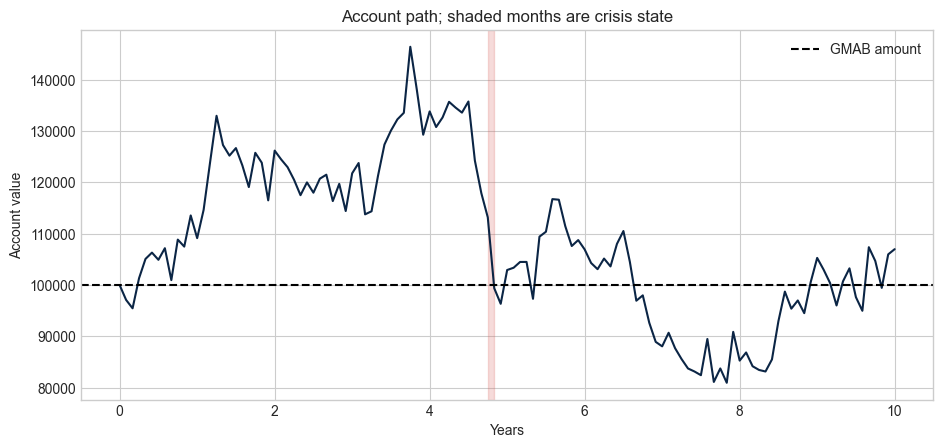

In [7]:
plot_states = states[0]
plot_account = accounts[0]
time = np.linspace(0, T, N_STEPS + 1)
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(time, plot_account, color=INK if "INK" in globals() else "#0B2545", linewidth=1.5)
for k in range(N_STEPS):
    if plot_states[k] == 1:
        ax.axvspan(time[k], time[k+1], color="#D95F59", alpha=0.22)
ax.axhline(G, color="black", linestyle="--", label="GMAB amount")
ax.set(title="Account path; shaded months are crisis state", xlabel="Years", ylabel="Account value")
ax.legend()
plt.show()


## 7. GMAB value and a smooth benchmark

For comparison, the smooth benchmark keeps the calm-state volatility at 16%.
The regime model has additional periods of high volatility, so the comparison
is deliberately a stress/model-risk experiment, not a calibration contest.


           model  GMAB_value   MC_SE  trigger_probability
      Smooth GBM 11,974.3388     NaN                  NaN
Regime switching 15,583.0298 75.2098               0.5584
Regime-model uplift: $3,608.69 (30.1%)


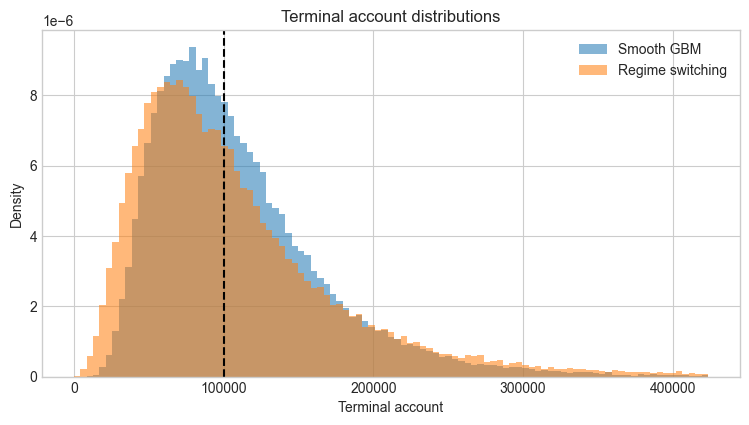

In [8]:
discounted_losses = np.exp(-r*T) * np.maximum(G-terminal, 0)
regime_price = discounted_losses.mean()
regime_se = discounted_losses.std(ddof=1) / np.sqrt(len(discounted_losses))
regime_trigger = (terminal < G).mean()

def gbm_put(A0, G, T, r, charge, sigma):
    d1 = (np.log(A0/G)+(r-charge+0.5*sigma**2)*T)/(sigma*np.sqrt(T))
    d2 = d1-sigma*np.sqrt(T)
    return G*np.exp(-r*T)*norm.cdf(-d2)-A0*np.exp(-charge*T)*norm.cdf(-d1)


smooth_price = gbm_put(A0, G, T, r, charge, SIGMAS[0])
result = pd.DataFrame([
    ["Smooth GBM", smooth_price, np.nan, np.nan],
    ["Regime switching", regime_price, regime_se, regime_trigger],
], columns=["model", "GMAB_value", "MC_SE", "trigger_probability"])
print(result.to_string(index=False))
print(f"Regime-model uplift: ${regime_price-smooth_price:,.2f} ({regime_price/smooth_price-1:.1%})")

fig, ax = plt.subplots(figsize=(9, 4.5))
gbm_rng = np.random.default_rng(SEED + 3)
gbm_terminal = A0*np.exp(
    (r-charge-0.5*SIGMAS[0]**2)*T
    + SIGMAS[0]*np.sqrt(T)*gbm_rng.standard_normal(len(terminal))
)
bins = np.linspace(0, np.quantile(np.concatenate([terminal, gbm_terminal]), 0.995), 100)
ax.hist(gbm_terminal, bins=bins, density=True, alpha=0.55, label="Smooth GBM")
ax.hist(terminal, bins=bins, density=True, alpha=0.55, label="Regime switching")
ax.axvline(G, color="black", linestyle="--")
ax.set(title="Terminal account distributions", xlabel="Terminal account", ylabel="Density")
ax.legend()
plt.show()


## 8. Limiting-case test: equal volatilities

If calm and crisis volatility are identical, the states should become
irrelevant. With the same normal shocks, the regime account must match GBM
path by path.


In [9]:
limit_rng = np.random.default_rng(SEED + 4)
z_limit = limit_rng.standard_normal((3_000, N_STEPS))
state_limit = states[:3_000]
equal_sigma_accounts = simulate_regime_accounts(
    A0, T, r, charge, np.array([0.16, 0.16]), state_limit, normals=z_limit
)
dt = T/N_STEPS
gbm_log_increments = (
    (r-charge-0.5*0.16**2)*dt + 0.16*np.sqrt(dt)*z_limit
)
gbm_same = A0*np.exp(np.column_stack([
    np.zeros(len(z_limit)), np.cumsum(gbm_log_increments, axis=1)
]))
max_difference = np.max(np.abs(equal_sigma_accounts-gbm_same))
print(f"Maximum pathwise difference with equal volatilities: {max_difference:.3e}")
assert np.allclose(equal_sigma_accounts, gbm_same, rtol=1e-12, atol=1e-8)


Maximum pathwise difference with equal volatilities: 5.821e-10


## 9. Sensitivity to crisis entry and persistence

We reuse the same uniform and normal arrays in every scenario so that changes
are driven by parameters rather than avoidable simulation noise.


           entry=0.005  entry=0.010  entry=0.020  entry=0.030
stay=0.70  12,724.4300  13,437.1600  14,691.0600  15,795.5200
stay=0.80  13,019.6600  13,999.1700  15,671.8700  17,078.5800
stay=0.90  13,823.2300  15,419.8000  17,975.6700  19,968.5300
stay=0.95  14,907.0600  17,227.2600  20,753.5100  23,258.9900


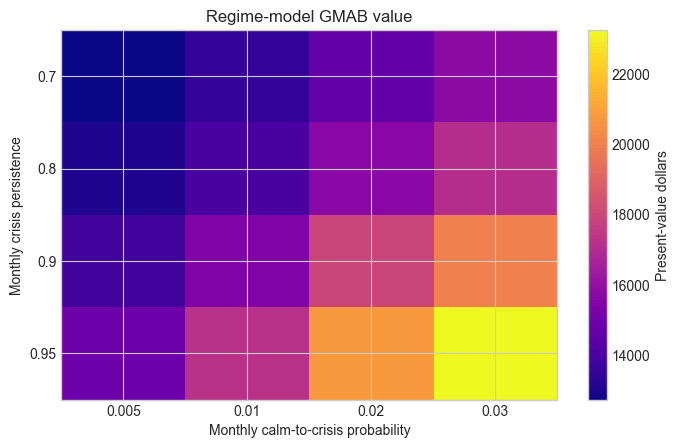

In [10]:
sens_paths = 20_000
sens_rng = np.random.default_rng(SEED + 5)
u_bank = sens_rng.random((sens_paths, N_STEPS))
z_bank = sens_rng.standard_normal((sens_paths, N_STEPS))
entry_grid = np.array([0.005, 0.010, 0.020, 0.030])
stay_grid = np.array([0.70, 0.80, 0.90, 0.95])
price_heat = np.empty((len(stay_grid), len(entry_grid)))

for i, stay in enumerate(stay_grid):
    for j, entry in enumerate(entry_grid):
        matrix = np.array([[1-entry, entry], [1-stay, stay]])
        scenario_states = simulate_states(
            matrix, sens_paths, N_STEPS, uniforms=u_bank
        )
        scenario_accounts = simulate_regime_accounts(
            A0, T, r, charge, SIGMAS, scenario_states, normals=z_bank
        )
        price_heat[i, j] = np.exp(-r*T)*np.maximum(
            G-scenario_accounts[:, -1], 0
        ).mean()

heat_df = pd.DataFrame(
    price_heat,
    index=[f"stay={x:.2f}" for x in stay_grid],
    columns=[f"entry={x:.3f}" for x in entry_grid],
)
print(heat_df.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(price_heat, aspect="auto", cmap="plasma")
ax.set_xticks(np.arange(len(entry_grid)), entry_grid)
ax.set_yticks(np.arange(len(stay_grid)), stay_grid)
ax.set(xlabel="Monthly calm-to-crisis probability", ylabel="Monthly crisis persistence", title="Regime-model GMAB value")
fig.colorbar(im, ax=ax, label="Present-value dollars")
plt.show()


## 10. Exercises

1. Interpret each row of $P^Q$ in one sentence.
2. Calculate expected calm and crisis run lengths.
3. Increase crisis volatility to 60% while reusing the same states and normals.
4. Explain why persistent volatility and one-time jumps create different path
   shapes even if they produce similar guarantee values.


## 11. Worked solutions


In [ ]:
# Exercise 2
print(f"Expected calm run:   {1/(1-P[0,0]):.2f} months")
print(f"Expected crisis run: {1/(1-P[1,1]):.2f} months")

# Exercise 3
high_crisis_accounts = simulate_regime_accounts(
    A0, T, r, charge, np.array([0.16, 0.60]),
    states, seed=SEED + 2
)
high_crisis_losses = np.exp(-r*T)*np.maximum(G-high_crisis_accounts[:, -1], 0)
print(f"Baseline regime price: ${regime_price:,.2f}")
print(f"60% crisis-volatility price: ${high_crisis_losses.mean():,.2f}")
assert high_crisis_losses.mean() > regime_price


## 12. Weekly takeaways

1. Transition rows describe next-state probabilities conditional on today.
2. Persistence controls the length of stressed episodes.
3. State-dependent volatility changes the distribution without changing the
   selected conditional risk-neutral drift.
4. A pricing transition matrix is an explicit assumption in this incomplete market.
5. Similar prices can hide very different path behavior.

### Weekly submission

- Completed notebook
- Plain-language transition-matrix interpretation
- One-page comparison of persistent stress and one-time crashes
